In [ ]:
%cd ..


In [ ]:
from pathlib import Path
import os
import h5py
import scipy.io


In [ ]:


path = "data/ninapro_db5/S2_E2_A1.mat"

mat = scipy.io.loadmat(path)
print(mat.keys())

In [ ]:
print(mat['emg'].shape)  # (number of samples, number of electrodes)
print(mat['acc'].shape)
print(mat['stimulus'].shape)  # (number of samples, 1)
print(mat['glove'].shape)
print(mat['subject'])
print(mat['exercise'])
print(mat['repetition'].shape)
print(mat['frequency'])
print(mat['sensor'])

In [ ]:
import numpy as np
emg = mat['emg']  # (number of samples, number of electrodes)
emg = np.array(emg, dtype=np.float32)
print(np.max(np.abs(emg)))  # Check the max absolute value for normalization

In [ ]:
stimulus = mat['stimulus']
repetition = mat['repetition']

print(np.unique(stimulus))  # Unique gesture labels
print(np.unique(repetition))  # Unique repetition numbers

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(25, 10))
plt.plot(stimulus, label='Stimulus (Gesture ID)')
plt.plot(repetition, label='Repetition')
plt.xlabel('Sample Index')
plt.ylabel('Value')
plt.title('Stimulus and Repetition Over Time')
plt.legend()
plt.show()

In [ ]:
restimulus = mat['restimulus']
rerepetition = mat['rerepetition']

print(np.unique(restimulus))  # Unique refined gesture labels
print(np.unique(rerepetition))  # Unique refined repetition numbers

In [ ]:
plt.figure(figsize=(25, 10))
plt.plot(restimulus, label='Refined Stimulus (Gesture ID)')
plt.plot(rerepetition, label='Refined Repetition')
plt.xlabel('Sample Index')
plt.ylabel('Value')
plt.title('Refined Stimulus and Repetition Over Time')
plt.legend()
plt.show()

## Check if the masking and segmenting script works with visualisation

In [ ]:
import h5py
from tqdm import tqdm



def get_global_gesture_id(exercise_id, stimulus_id):
    """NinaPro DB5 has a unique gesture distribution across exercises:
    
    Each exercise has a different set of gestures:

    Exercise 1 (2 in fname, B in docs): 17 gestures (1-17)
    Exercise 2 (3 in fname, C in docs): 23 gestures (18-40)
    Exercise 3 (1 in fname, A in docs): 12 gestures (41-52)
    """

    if stimulus_id == 0: return 0 # Rest is always 0
    
    # Offsets based on the 17, 23, 12 distribution
    if exercise_id == 1:
        return stimulus_id
    elif exercise_id == 2:
        return stimulus_id + 17
    elif exercise_id == 3:
        return stimulus_id + 17 + 23
    return stimulus_id

dataset_dir = "data/ninapro_db5"
output_file = "test.hdf5"

dataset_dir = Path(dataset_dir)
mat_files = sorted(dataset_dir.glob("*.mat"))

with h5py.File(output_file, 'w') as f:
    root = f.create_group("ninapro_db5")
    
    for fpath in tqdm(mat_files, desc="Converting NinaPro DB5"):
        mat = scipy.io.loadmat(str(fpath))
        
        # Extract basic subject info
        # Matlab stores strings/scalars in nested arrays; we flatten them
        subject_id = int(mat['subject'][0][0])
        exercise_id = int(mat['exercise'][0][0])
        fs = int(mat['frequency'][0][0])
        
        subj_key = f"S{subject_id}"
        if subj_key not in root:
            subj_group = root.create_group(subj_key)
            # Static Metadata from the website spec
            subj_group.attrs['age'] = int(mat['age'][0][0])
            subj_group.attrs['gender'] = str(mat['gender'][0])
            subj_group.attrs['weight_kg'] = float(mat['weight'][0][0])
            subj_group.attrs['height_cm'] = float(mat['height'][0][0])
            subj_group.attrs['laterality'] = str(mat['laterality'][0])
            subj_group.attrs['circumference_cm'] = float(mat['circumference'][0][0])
        else:
            subj_group = root[subj_key]

        # Continuous data arrays
        emg = mat['emg'].astype(np.float32)       # (T, 16)
        acc = mat['acc'].astype(np.float32)       # (T, 3) - Note: Only 3 cols for 1st Myo
        glove = mat['glove'].astype(np.float32)   # (T, 22)

        emg /= 128.0  # Normalize Myo EMG to [-1, 1] if raw values are in [-128, 127]
        
        # Use 'restimulus' and 'rerepetition' for refined labels
        stimulus = mat['restimulus'].flatten()
        repetition = mat['rerepetition'].flatten()
        
        # Group by refined trial (rerepetition)
        unique_reps = np.unique(repetition)
        unique_stimuli = np.unique(stimulus)
        print(unique_stimuli)
        i = 0
        
        for rep_idx in unique_reps:
            if rep_idx == 0: continue # Skip rest periods
            
            for stim_idx in unique_stimuli:
                if stim_idx == 0: continue # Skip rest periods
            
                mask = ((repetition == rep_idx) & (stimulus == stim_idx))
                if not np.any(mask):
                    continue
                gesture_ids = np.unique(stimulus[mask])
                print(gesture_ids)
                print(rep_idx)
                print(stim_idx)

                plt.figure(figsize=(25, 10))
                plt.plot(stimulus, label='Refined Stimulus (Gesture ID)')
                plt.plot(repetition, label='Refined Repetition')
                plt.plot(mask.astype(int), label='Current Repetition Mask')  # Highlight current repetition
                plt.xlabel('Sample Index')
                plt.ylabel('Value')
                plt.title('Refined Stimulus and Repetition Over Time')
                plt.legend()
                plt.show()
                i += 1
                if i > 3:
                    break
                continue
                
                # Filter out the '0' label within a repetition mask if it exists
                gesture_ids = gesture_ids[gesture_ids != 0]
                if len(gesture_ids) == 0: continue
                
                gesture_id = int(gesture_ids[0])
                gesture_id = get_global_gesture_id(exercise_id, gesture_id)

                # Create sample group (E=Exercise, R=Repetition, G=Gesture)
                sample_name = f"E{exercise_id}_R{rep_idx}_G{gesture_id}"
                sample_group = subj_group.create_group(sample_name)
                
                # Per-sample Metadata
                sample_group.attrs['gesture_id'] = gesture_id
                sample_group.attrs['repetition_id'] = rep_idx
                
                # 1. EMG (T, 16) 
                # NinaPro EMG is typically recorded in mV or raw units. 
                # Check if you need to scale. If raw Myo, use emg /= 128.0
                sample_group.create_dataset("emg", data=emg[mask], compression="lzf")
                
                # 2. Accel (T, 3)
                sample_group.create_dataset("accel", data=acc[mask], compression="lzf")
                
                # 3. Glove (T, 22) - Kinematic ground truth
                sample_group.create_dataset("glove", data=glove[mask], compression="lzf")
        

In [1]:
%cd ..

/home/willraftery/PhD/projects/github/emg-stream


In [5]:
import h5py
import numpy as np

with h5py.File("data/ninapro_db5/ninapro_db5.hdf5", 'r') as f:
    root = f["ninapro_db5"]
    sample_lengths = []
    for subj_key in root.keys():
        print(f"Subject: {subj_key}")
        subj_group = root[subj_key]
        print(f"  Age: {subj_group.attrs['age']}")
        subj_group = root[subj_key]
        for sample_key in subj_group.keys():
            sample_group = subj_group[sample_key]
            emg_data = sample_group["emg"][:]
            print(f"  Sample: {sample_key}, EMG shape: {emg_data.shape}")
            sample_lengths.append(emg_data.shape[0])

sample_lengths = np.array(sample_lengths)
avg_length = np.mean(sample_lengths)
std = np.std(sample_lengths)
min_length = np.min(sample_lengths)
max_length = np.max(sample_lengths)
print(f"Sample Lengths - Avg: {avg_length:.2f}, Std: {std:.2f}, Min: {min_length}, Max: {max_length}")
print(f"Total Samples: {len(sample_lengths)}")

Subject: S1
  Age: 23
  Sample: E1_T0_G0, EMG shape: (1780, 16)
  Sample: E1_T100_G0, EMG shape: (1090, 16)
  Sample: E1_T101_G9, EMG shape: (741, 16)
  Sample: E1_T102_G0, EMG shape: (411, 16)
  Sample: E1_T103_G9, EMG shape: (836, 16)
  Sample: E1_T104_G0, EMG shape: (1024, 16)
  Sample: E1_T105_G9, EMG shape: (711, 16)
  Sample: E1_T106_G0, EMG shape: (1121, 16)
  Sample: E1_T107_G9, EMG shape: (758, 16)
  Sample: E1_T108_G0, EMG shape: (1016, 16)
  Sample: E1_T109_G10, EMG shape: (804, 16)
  Sample: E1_T10_G0, EMG shape: (895, 16)
  Sample: E1_T110_G0, EMG shape: (993, 16)
  Sample: E1_T111_G10, EMG shape: (836, 16)
  Sample: E1_T112_G0, EMG shape: (965, 16)
  Sample: E1_T113_G10, EMG shape: (766, 16)
  Sample: E1_T114_G0, EMG shape: (1038, 16)
  Sample: E1_T115_G10, EMG shape: (806, 16)
  Sample: E1_T116_G0, EMG shape: (976, 16)
  Sample: E1_T117_G10, EMG shape: (798, 16)
  Sample: E1_T118_G0, EMG shape: (1030, 16)
  Sample: E1_T119_G10, EMG shape: (770, 16)
  Sample: E1_T11_G1, E

In [ ]:
import h5py
with h5py.File("data/ninapro_db5/ninapro_db5.hdf5", 'r') as f:
    root = f["ninapro_db5"]
    for subj_key in root.keys():
        print(f"Subject: {subj_key}")
        subj_group = root[subj_key]
        print(subj_group.attrs.keys())  # Print static metadata
        print(subj_group.attrs['age'], subj_group.attrs['gender'], subj_group.attrs['weight_kg'], subj_group.attrs['height_cm'], subj_group.attrs['laterality'], subj_group.attrs['circumference_cm'])
        print(subj_group.keys())  # List all samples for this subject
        for sample_key in subj_group.keys():
            print(f"  Sample: {sample_key}")
            sample_group = subj_group[sample_key]
            print(sample_group.attrs.keys())  # Print per-sample metadata
            emg_data = sample_group["emg"][:]
            accel_data = sample_group["accel"][:]
            glove_data = sample_group["glove"][:]
            print(f"    EMG shape: {emg_data.shape}")
            print(f"    Accel shape: {accel_data.shape}")
            print(f"    Glove shape: {glove_data.shape}")
            

In [ ]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

def analyze_ninapro_hdf5(file_path, root_key="ninapro_db5"):
    data_records = []
    
    with h5py.File(file_path, 'r') as f:
        root = f[root_key]
        subjects = list(root.keys())
        
        for subj in tqdm(subjects, desc="Analyzing subjects"):
            subj_group = root[subj]
            subj_meta = dict(subj_group.attrs)
            
            for trial_name in subj_group.keys():
                # Skip attributes, focus on trial groups
                if not isinstance(subj_group[trial_name], h5py.Group):
                    continue
                    
                trial = subj_group[trial_name]
                trial_meta = dict(trial.attrs)
                
                # Signal metrics
                emg_shape = trial['emg'].shape
                duration_sec = emg_shape[0] / trial_meta.get('sample_rate', 200)
                
                # Combine metadata for flat dataframe
                record = {
                    **subj_meta,
                    **trial_meta,
                    'trial_name': trial_name,
                    'num_samples': emg_shape[0],
                    'duration_sec': duration_sec,
                    'emg_mean': np.mean(trial['emg']),
                    'emg_std': np.std(trial['emg'])
                }
                data_records.append(record)

    df = pd.DataFrame(data_records)
    
    # --- VISUALIZATION ---
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    plt.subplots_adjust(hspace=0.4)

    # 1. Gesture Distribution (Class Balance)
    
    sns.countplot(data=df, x='gesture_id', ax=axes[0,0], palette='viridis')
    axes[0,0].set_title("Sample Count per Gesture ID")
    axes[0,0].set_yscale('log') # Log scale helps see active gestures vs heavy Rest counts
    
    # 2. Trial Durations
    sns.histplot(data=df, x='duration_sec', hue='intra_session_split', multiple="stack", ax=axes[0,1])
    axes[0,1].set_title("Distribution of Trial Durations (Seconds)")

    # 3. Data Leakage Audit (Subject vs Repetition Split)
    
    leak_table = pd.crosstab(df['subject_id'], df['subject_split'])
    sns.heatmap(leak_table, annot=True, cbar=False, ax=axes[1,0], cmap='Blues')
    axes[1,0].set_title("Subject-to-Split Mapping (Zero-Shot Check)")

    # 4. Signal Quality (Mean vs Std per Subject)
    sns.scatterplot(data=df, x='emg_mean', y='emg_std', hue='subject_id', alpha=0.5, ax=axes[1,1])
    axes[1,1].set_title("Signal Energy (Mean vs Std) - Quality Check")
    axes[1,1].get_legend().remove()

    plt.show()

    # --- SUMMARY STATS ---
    print(f"\n{'='*30}\nNINAPRO DB5 AUDIT REPORT\n{'='*30}")
    print(f"Total Subjects: {df['subject_id'].nunique()}")
    print(f"Total Gesture Trials: {len(df)}")
    print(f"Total EMG Hours: {df['duration_sec'].sum() / 3600:.2f}h")
    print(f"\nSplit Distribution (Sessions):")
    print(df['intra_session_split'].value_counts(normalize=True) * 100)
    print(  f"\nSplit Distribution (Subjects):")
    print(df['subject_split'].value_counts(normalize=True) * 100)
    
    return df

# Usage
# df = analyze_ninapro_hdf5("data/ninapro_db5/ninapro_db5.hdf5")

Analyzing subjects: 100%|██████████| 10/10 [00:01<00:00,  5.49it/s]
/tmp/ipykernel_33335/1978214130.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='gesture_id', ax=axes[0,0], palette='viridis')


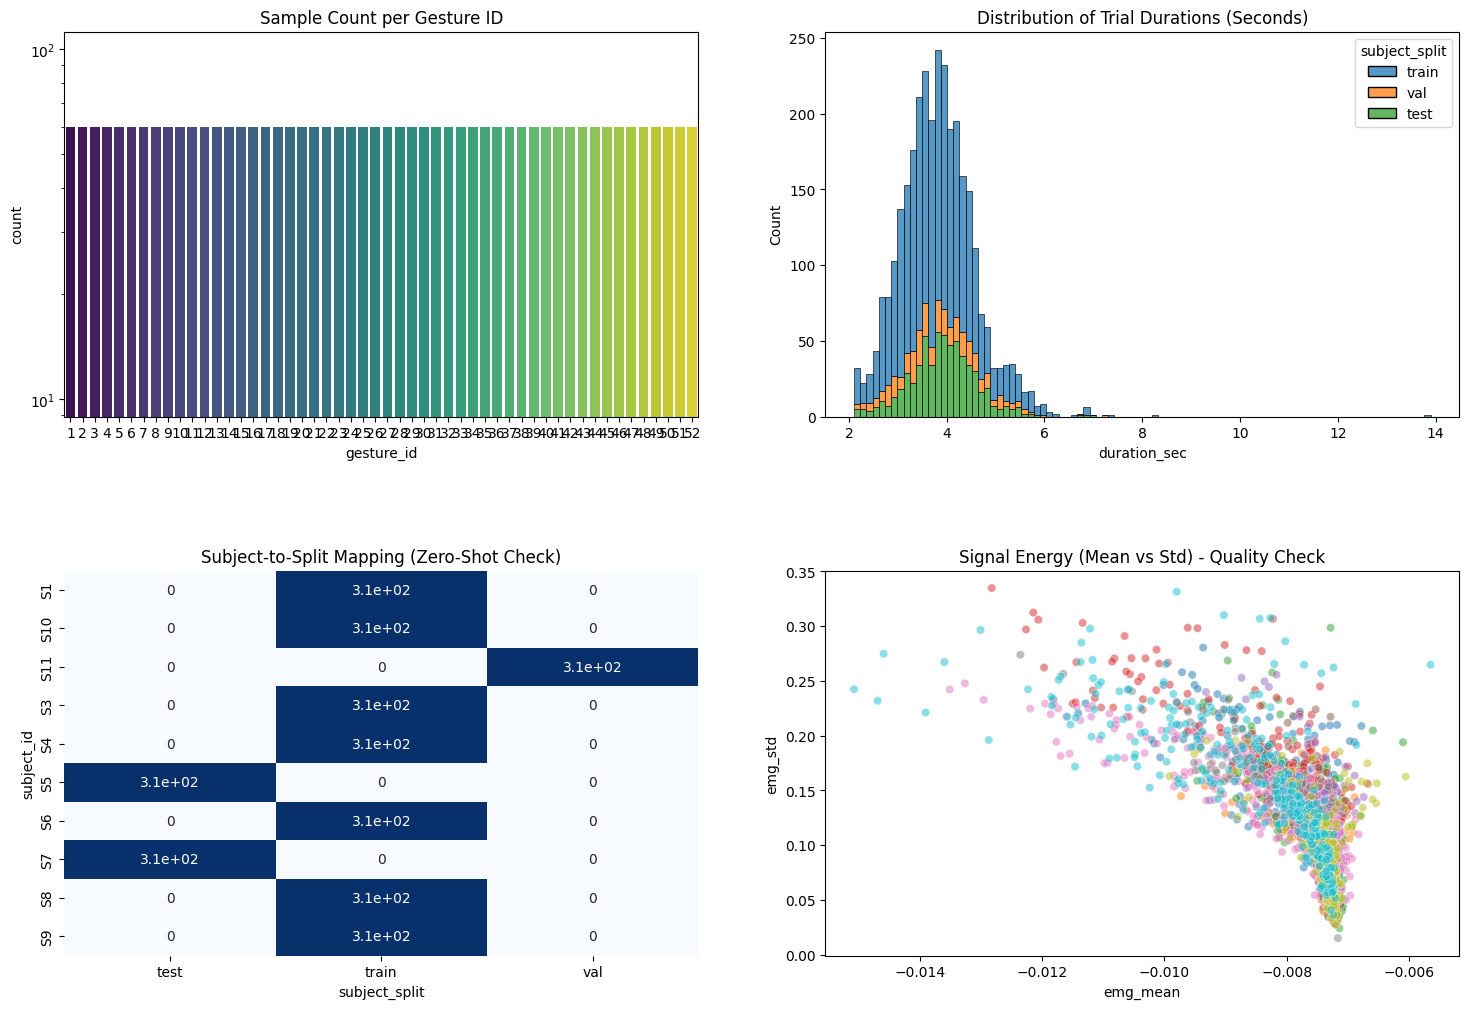


NINAPRO DB5 AUDIT REPORT
Total Subjects: 10
Total Gesture Trials: 3120
Total EMG Hours: 3.31h

Split Distribution (Sessions):
intra_session_split
train    66.666667
test     16.666667
val      16.666667
Name: proportion, dtype: float64

Split Distribution (Subjects):
subject_split
train    70.0
test     20.0
val      10.0
Name: proportion, dtype: float64


In [18]:
df = analyze_ninapro_hdf5("data/ninapro_db5/ninapro_db5.hdf5")

In [9]:
import h5py
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm

def analyze_class_length_distribution(hdf5_path, root_key):
    """
    Generic analyzer for the Unified Biosignal HDF5 format.
    Focuses on identifying potential label leakage through signal length distribution.
    
    Args:
        hdf5_path (str): Path to the .hdf5 file.
        root_key (str): The root group name (e.g., 'epn612' or 'ninapro_db5').
    """
    data = []
    
    with h5py.File(hdf5_path, 'r') as f:
        if root_key not in f:
            print(f"Error: Root key '{root_key}' not found in {hdf5_path}")
            return
            
        root = f[root_key]
        
        # Crawl subjects
        for subj_id in tqdm(root.keys(), desc="Extracting trial lengths"):
            subj_group = root[subj_id]
            
            # Crawl sessions/trials
            for sess_id in subj_group.keys():
                if not isinstance(subj_group[sess_id], h5py.Group):
                    continue
                
                sess_group = subj_group[sess_id]
                
                # Ensure emg dataset exists
                if 'emg' not in sess_group:
                    continue
                    
                # Extract metadata
                gesture_id = sess_group.attrs.get('gesture_id', -1)
                sample_rate = sess_group.attrs.get('sample_rate', 200)
                
                # Get length T from shape (T, C)
                length_samples = sess_group['emg'].shape[0]
                duration_sec = length_samples / sample_rate
                
                data.append({
                    'subject_id': subj_id,
                    'gesture_id': gesture_id,
                    'length_samples': length_samples,
                    'duration_sec': duration_sec
                })

    df = pd.DataFrame(data)
    
    if df.empty:
        print("No trials found to analyze.")
        return

    # --- Plotting ---
    plt.figure(figsize=(16, 8))
    
    # Sort by gesture_id for readability
    df = df.sort_values('gesture_id')
    
    # We use a boxenplot or boxplot to show the distribution
    sns.boxplot(data=df, x='gesture_id', y='duration_sec', palette='husl')
    
    # Add a horizontal line for the mean duration to highlight outliers
    plt.axhline(df['duration_sec'].mean(), color='red', linestyle='--', alpha=0.6, label='Global Mean')
    
    plt.title(f"Signal Length Distribution per Class: {root_key.upper()}", fontsize=16)
    plt.xlabel("Gesture ID", fontsize=12)
    plt.ylabel("Duration (seconds)", fontsize=12)
    plt.legend()
    plt.grid(axis='y', linestyle=':', alpha=0.7)
    
    # If there are many classes (e.g., EPN612), thin out the x-labels
    if df['gesture_id'].nunique() > 20:
        plt.xticks(rotation=90, fontsize=8)
    
    plt.tight_layout()
    plt.show()

    # --- Statistical Leakage Check ---
    # Calculate variance of lengths per class
    stats = df.groupby('gesture_id')['duration_sec'].agg(['mean', 'std', 'count'])
    print("\n--- Length Statistics per Class ---")
    print(stats.head(10)) # Print first 10 for brevity
    
    # Check if any class is perfectly predictable by length (std == 0)
    leakage_candidates = stats[stats['std'] < 0.001]
    if not leakage_candidates.empty:
        print("\n⚠️ WARNING: Potential Label Leakage Detected!")
        print("The following classes have zero or near-zero variation in length.")
        print("A model could simply learn the sequence length to identify these classes:")
        print(leakage_candidates.index.tolist())
    else:
        print("\n✅ Clean: No classes have a unique, fixed length signature.")

Extracting trial lengths: 100%|██████████| 10/10 [00:00<00:00, 36.23it/s]
/tmp/ipykernel_33335/3475271319.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='gesture_id', y='duration_sec', palette='husl')


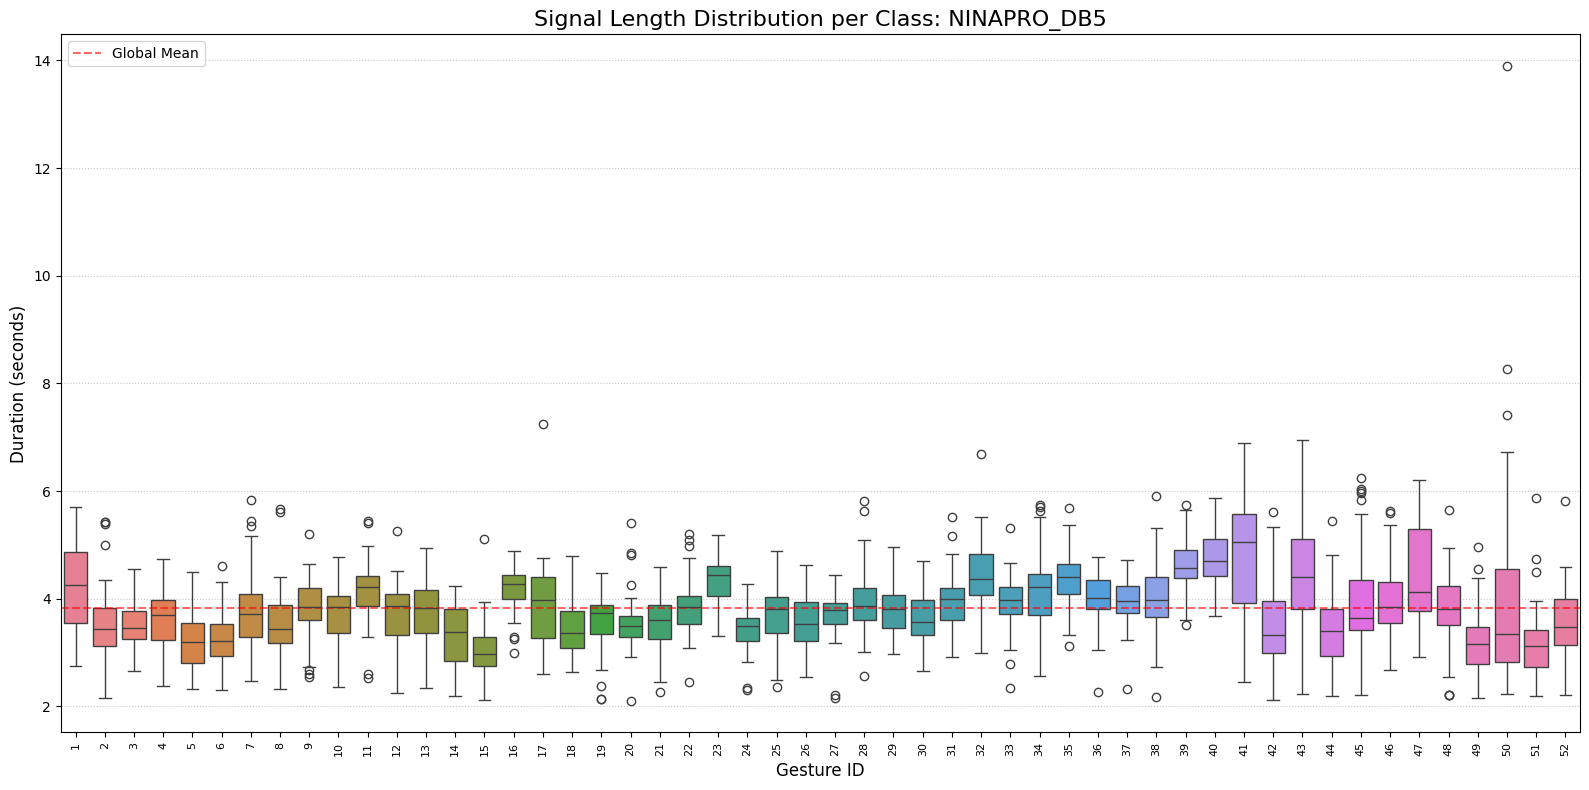


--- Length Statistics per Class ---
                mean       std  count
gesture_id                           
1           4.221917  0.818598     60
2           3.540167  0.695945     60
3           3.564167  0.461686     60
4           3.625917  0.485369     60
5           3.196250  0.499138     60
6           3.262333  0.478385     60
7           3.724667  0.712339     60
8           3.518750  0.621671     60
9           3.849000  0.506393     60
10          3.650583  0.602811     60

✅ Clean: No classes have a unique, fixed length signature.


In [10]:
analyze_class_length_distribution("data/ninapro_db5/ninapro_db5.hdf5", root_key="ninapro_db5")